In [ ]:
#Member1: Hana Khaled Abdelhamed soliman 20240650
#Member2: Jana Ahmed Farahat Hassan 20240759

In [110]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

np.random.seed(42)

In [111]:
from sklearn.datasets import load_breast_cancer

In [112]:
data = load_breast_cancer()
X = data.data
y= data.target


In [113]:
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("feature names:", data.feature_names)
print("classes: ", data.target_names)

Shape of X: (569, 30)
Shape of y: (569,)
feature names: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
classes:  ['malignant' 'benign']


In [114]:
#Task 1: Data Preparation
#wrote a stratified train-test split function to ensure that the class distribution is preserved in both the training and testing sets. 
# This is important for imbalanced datasets like the breast cancer dataset, where one class may be underrepresented.

In [115]:

def train_test_split(X, y, test_size=0.2, seed=42):

    np.random.seed(seed)

    classes = np.unique(y)

    train_indices = []
    test_indices = []

    # Calculate how many samples we need in the test set
    total_test = round(len(y) * test_size)

    # Get the number of test samples for each class
    class_indices = {}
    test_counts = {}

    for c in classes:
        indices = np.where(y == c)[0]
        np.random.shuffle(indices)

        class_indices[c] = indices

        # Initial allocation using floor
        test_counts[c] = int(len(indices) * test_size)

    # Distribute any remaining test samples
    remaining = total_test - sum(test_counts.values())

    fractions = {
        c: len(class_indices[c]) * test_size - test_counts[c]
        for c in classes
    }

    for c in sorted(classes, key=lambda c: fractions[c], reverse=True):
        if remaining == 0:
            break
        test_counts[c] += 1
        remaining -= 1

    for c in classes:
        indices = class_indices[c]
        n_test = test_counts[c]

        test_indices.extend(indices[:n_test])
        train_indices.extend(indices[n_test:])

    np.random.shuffle(train_indices)
    np.random.shuffle(test_indices)

    X_train = X[train_indices]
    X_test = X[test_indices]

    y_train = y[train_indices]
    y_test = y[test_indices]

    return X_train, X_test, y_train, y_test


In [116]:
X_train, X_test, y_train, y_test = train_test_split(X, y)

In [117]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (455, 30)
X_test: (114, 30)
y_train: (455,)
y_test: (114,)


In [118]:
print("Original distribution:")
print(np.unique(y, return_counts=True))

print("Training distribution:")
print(np.unique(y_train, return_counts=True))

print("Testing distribution:")
print(np.unique(y_test, return_counts=True))

Original distribution:
(array([0, 1]), array([212, 357]))
Training distribution:
(array([0, 1]), array([169, 286]))
Testing distribution:
(array([0, 1]), array([43, 71]))


In [119]:
#calculating the prior probabilities of each class
prior_0 = y_train[y_train == 0].size / y_train.size
prior_1 = y_train[y_train == 1].size / y_train.size

In [120]:
X_train_malignant = X_train[y_train==0]
X_train_benign = X_train[y_train==1]

In [121]:
print(X_train_malignant.shape)
print(X_train_benign.shape)

(169, 30)
(286, 30)


In [122]:
mean_malignant = np.mean(X_train_malignant, axis=0)
mean_benign = np.mean(X_train_benign, axis=0)

In [123]:
print(mean_malignant.shape)
print(mean_benign.shape)

(30,)
(30,)


In [124]:
variance_malignant = np.var(X_train_malignant, axis=0)
variance_benign = np.var(X_train_benign, axis=0)

In [125]:
#variance smoothing to avoid zero variance
var_smoothing = 1e-9
epsilon = var_smoothing * np.var(X_train, axis=0).max()
variance_malignant += epsilon
variance_benign += epsilon

print("Epsilon:", epsilon)
print("Malignant variances:", variance_malignant)
print("Benign variances:", variance_benign)

Epsilon: 0.00030920868184538094
Malignant variances: [1.05515221e+01 1.42094050e+01 4.95082616e+02 1.41324491e+05
 4.73623907e-04 3.05941124e-03 5.94564903e-03 1.54936418e-03
 9.86948981e-04 3.64192051e-04 1.31230670e-01 2.44934429e-01
 7.19849121e+00 4.18922801e+03 3.18653745e-04 6.66067158e-04
 7.84492476e-04 3.40447755e-04 3.99018452e-04 3.13568130e-04
 1.79745800e+01 3.01706982e+01 8.67917216e+02 3.49756250e+05
 8.19321761e-04 2.83234715e-02 3.18996265e-02 2.56688092e-03
 5.64869780e-03 7.38197261e-04]
Benign variances: [3.24441339e+00 1.73330315e+01 1.41832976e+02 1.81441094e+04
 5.01262307e-04 1.39166757e-03 2.16642144e-03 5.62922591e-04
 9.29067115e-04 3.55268563e-04 1.26255721e-02 3.66224552e-01
 5.76530303e-01 7.12981841e+01 3.18592965e-04 5.44639796e-04
 1.50993179e-03 3.43193959e-04 3.55972079e-04 3.16168709e-04
 3.97056640e+00 3.10083680e+01 1.80332587e+02 2.67163383e+04
 7.23831541e-04 8.51680148e-03 2.03630999e-02 1.58520907e-03
 2.04734648e-03 5.02459858e-04]


In [126]:
#task 2  : Gaussian Naive Bayes Implementation
# fit computes the class priors,mean,variance of each feature
# predict computes log prior + sum of log gaussian likelihoods for all
#returns the class with the highest score
#predict_proba turns log scores into probabilities using the softmax function

In [127]:
#Gaussian Naive Bayes Classifier

class GaussianNaiveBayes:
    def __init__(self,var_smoothing=1e-9):
        self.var_smoothing = var_smoothing
        
    def fit(self, X, y):
        self.classes_ = np.unique(y)
        
        self.class_prior_ = []
        for c in self.classes_:
            count = np.sum(y == c)
            prior = count / len(y)
            self.class_prior_.append(prior)
        
        self.class_prior_ = np.array(self.class_prior_)

        #mean and variance for each class
        self.theta_ = []
        self.var_ = []

        for c in self.classes_:
            X_class = X[y == c]
            class_mean = np.mean(X_class, axis=0)
            self.theta_.append(class_mean)

            class_var = np.var(X_class, axis=0)
            self.var_.append(class_var)

        self.theta_ = np.array(self.theta_)
        self.var_ = np.array(self.var_)

        self.epsilon_ = self.var_smoothing * np.max(np.var(X, axis=0))

        self.var_ = self.var_ + self.epsilon_

        return self

    def predict(self, X):
        scores = []

        for i in range(len(self.classes_)):
            mean = self.theta_[i]
            variance = self.var_[i]
            log_prior = np.log(self.class_prior_[i])
            log_likelihood = -0.5 * np.sum(np.log(2 * np.pi * variance)+ ((X - mean) ** 2 / variance),axis=1)
            class_score = log_prior + log_likelihood
            scores.append(class_score)

        scores = np.array(scores).T
        predictions = self.classes_[np.argmax(scores, axis=1)]

        return predictions

    def predict_proba(self, X):
        scores = []
        for i in range(len(self.classes_)):
            mean = self.theta_[i]
            variance = self.var_[i]
            log_prior = np.log(self.class_prior_[i])
            log_likelihood = -0.5 * np.sum(np.log(2 * np.pi * variance) + ((X - mean) ** 2 / variance), axis=1)
            scores.append(log_prior + log_likelihood)

        scores = np.array(scores).T                      
        m = np.max(scores, axis=1, keepdims=True)         
        exp_scores = np.exp(scores - m)
        return exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

In [128]:
#sanity check

#small dataset created 
X_small = np.array([[1],[2],[3],[6],[7],[8]])
y_small = np.array([0, 0, 0, 1, 1, 1])
# 2. Manual calculations using a calculator
# Class 0 [1, 2, 3]
# mean_0 = (1 + 2 + 3) / 3 = 2
# var_0 = ((1-2)^2 + (2-2)^2 + (3-2)^2) / 3 = (1 + 0 + 1) / 3 = 0.666667
# Class 1 [6, 7, 8]
# mean_1 = (6 + 7 + 8) / 3 = 7
# var_1 = ((6-7)^2 + (7-7)^2 + (8-7)^2) / 3 = (1 + 0 + 1) / 3 = 0.666667
# prior_0 = 3 / 6 = 0.5
# prior_1 = 3 / 6 = 0.5

#Fit our Gaussian Naive Bayes model
small_model = GaussianNaiveBayes(var_smoothing=0)
small_model.fit(X_small, y_small)
print("Classes:", small_model.classes_)
print("Means:\n", small_model.theta_)
print("Variances:\n", small_model.var_)
print("Priors:", small_model.class_prior_)

# P(x|c) = 1 / sqrt(2*pi*var_c) *exp(-(x - mean_c)^2 / (2*var_c))
#class 0:
# P(2|0) = 1 / sqrt(2*pi*(2/3)) * exp(0) = 0.4886025
#class 1:
# P(2|1) = 1 / sqrt(2*pi*(2/3)) * exp(-(2-7)^2 / (2*(2/3))) = app. 3.515e-9
# Bayes' theorem:
# P(0|2) = P(2|0)*P(0) / (P(2|0)*P(0) + P(2|1)*P(1)) =  app. 0.999999993
# P(1|2) = 1 - P(0|2) = app. 0.00000000719   (7.19e-9)

new_sample = np.array([[2]])
print("Posterior from my class:", small_model.predict_proba(new_sample))
print("Posterior by hand      : [0.999999993, 0.00000000719]")

#Test model 
prediction = small_model.predict(new_sample)
print("\nNew sample:", new_sample)
print("Predicted class:", prediction)
# Expected prediction: [0]

assert np.allclose(small_model.theta_.ravel(), [2, 7])
assert np.allclose(small_model.var_.ravel(), [2/3, 2/3])
assert np.allclose(small_model.class_prior_, [0.5, 0.5])
assert np.allclose(small_model.predict_proba(new_sample), [[0.999999993, 7.19e-9]], atol=1e-8)
print("Sanity check passed: my class matches the hand calculation.")


Classes: [0 1]
Means:
 [[2.]
 [7.]]
Variances:
 [[0.66666667]
 [0.66666667]]
Priors: [0.5 0.5]
Posterior from my class: [[9.99999993e-01 7.19413298e-09]]
Posterior by hand      : [0.999999993, 0.00000000719]

New sample: [[2]]
Predicted class: [0]
Sanity check passed: my class matches the hand calculation.


In [129]:
#task 1 last point, Does GNB need feature scaling?

mean_train = X_train.mean(axis=0)
std_train = X_train.std(axis=0)
X_train_scaled = (X_train - mean_train) / std_train
X_test_scaled = (X_test - mean_train) / std_train

model_raw = GaussianNaiveBayes().fit(X_train, y_train)
model_scaled = GaussianNaiveBayes().fit(X_train_scaled, y_train)

acc_raw = np.mean(model_raw.predict(X_test) == y_test)
acc_scaled = np.mean(model_scaled.predict(X_test_scaled) == y_test)
print("Accuracy without scaling:", acc_raw)
print("Accuracy with scaling   :", acc_scaled)


#No. Accuracy is identical with and without
#standardization (both 0.9386). GNB gives every feature its own mean and variance
#so standardizing only rescales each feature own bell curve and
#doesn't change which class gets the higher score.

Accuracy without scaling: 0.9385964912280702
Accuracy with scaling   : 0.9385964912280702


In [130]:
# Task 3: Evaluation Metrics from Scratch
# defined feature_names and class_names so they can be used in the next tasks

In [131]:
feature_names = data.feature_names
class_names = data.target_names   # ['malignant', 'benign']

In [132]:
def accuracy(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return float(np.mean(y_true == y_pred))

def confusion_matrix(y_true, y_pred, classes):
    """k x k array: rows = true class, columns = predicted class."""
    classes = np.asarray(classes)
    k = len(classes)
    index = {c: i for i, c in enumerate(classes)}
    t = np.array([index[v] for v in y_true])
    p = np.array([index[v] for v in y_pred])
    cm = np.zeros((k, k), dtype=int)
    np.add.at(cm, (t, p), 1)
    return cm

def _safe_div(a, b):
    """Element-wise a/b, returning 0 where b == 0."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    out = np.zeros_like(a)
    np.divide(a, b, out=out, where=(b != 0))
    return out

def precision_recall_f1(y_true, y_pred, classes):
    """Returns per-class arrays and the macro average."""
    cm = confusion_matrix(y_true, y_pred, classes)
    tp = np.diag(cm).astype(float)
    pred_pos = cm.sum(axis=0)     # how often each class is predicted
    actual_pos = cm.sum(axis=1)   # true count of each class
    precision = _safe_div(tp, pred_pos)
    recall = _safe_div(tp, actual_pos)
    f1 = _safe_div(2 * precision * recall, precision + recall)
    return {"precision": precision, "recall": recall, "f1": f1,
            "macro": {"precision": precision.mean(), "recall": recall.mean(), "f1": f1.mean()}}

def plot_confusion(cm, labels, title):
    fig, ax = plt.subplots(figsize=(6, 5))          # wider figure
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    ax.set_title(title, fontsize=12, pad=12)        # smaller font + padding
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max()/2 else "black", fontsize=14)
    fig.colorbar(im, ax=ax, label="Count", fraction=0.046, pad=0.04)  # keeps colorbar matched to the plot height
    plt.tight_layout(); plt.show()

In [133]:
yt = np.array([0, 0, 1, 1, 2]); yp = np.array([0, 0, 0, 1, 0])
r = precision_recall_f1(yt, yp, [0, 1, 2])
print(confusion_matrix(yt, yp, [0, 1, 2]))
print(r["precision"], r["recall"], r["f1"])   # class 2 never predicted -> 0, no crash

[[2 0 0]
 [1 1 0]
 [1 0 0]]
[0.5 1.  0. ] [1.  0.5 0. ] [0.66666667 0.66666667 0.        ]


Accuracy: 0.9386

class        precision    recall        f1
malignant       0.8913    0.9535    0.9213
benign          0.9706    0.9296    0.9496
macro avg       0.9309    0.9415    0.9355


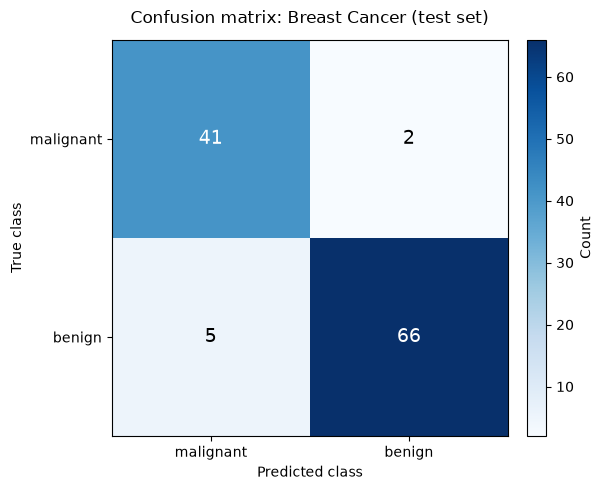

In [134]:
gnb = GaussianNaiveBayes(var_smoothing=1e-9).fit(X_train, y_train)
y_pred = gnb.predict(X_test)
classes = gnb.classes_

acc = accuracy(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, classes)
res = precision_recall_f1(y_test, y_pred, classes)

print(f"Accuracy: {acc:.4f}\n")
print(f"{'class':<12}{'precision':>10}{'recall':>10}{'f1':>10}")
for i, c in enumerate(classes):
    print(f"{class_names[c]:<12}{res['precision'][i]:>10.4f}{res['recall'][i]:>10.4f}{res['f1'][i]:>10.4f}")
m = res["macro"]
print(f"{'macro avg':<12}{m['precision']:>10.4f}{m['recall']:>10.4f}{m['f1']:>10.4f}")
plot_confusion(cm, [class_names[c] for c in classes], "Confusion matrix: Breast Cancer (test set)")

In [135]:
# Task 4(a): Breaking the naive assumption
# picked the most informative feature and added 0, 1, 3, 5 and 10 extra copies of it
# retrained each time and plotted the accuracy and the average maximum predicted probability

Most informative feature: worst concave points (score 2.49)
extra copies  accuracy  avg max prob
           0    0.9386        0.9995
           1    0.9386        0.9997
           3    0.9386        0.9987
           5    0.9474        0.9984
          10    0.9386        0.9941


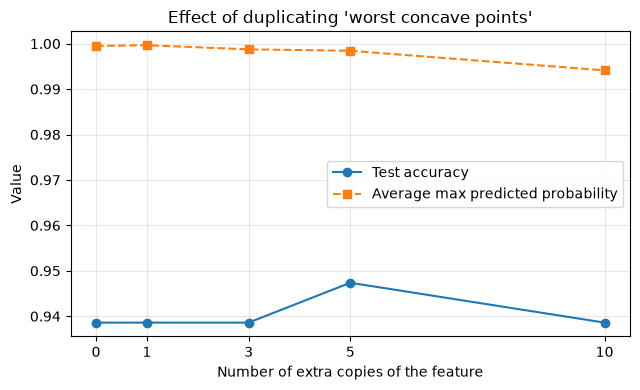

In [136]:
m0, m1 = X_train[y_train == 0].mean(0), X_train[y_train == 1].mean(0)
s0, s1 = X_train[y_train == 0].std(0), X_train[y_train == 1].std(0)
score = np.abs(m0 - m1) / np.sqrt((s0**2 + s1**2) / 2)
best = int(np.argmax(score))
print("Most informative feature:", feature_names[best], f"(score {score[best]:.2f})")

def add_copies(X, j, n):
    return np.hstack([X] + [X[:, [j]]] * n) if n > 0 else X.copy()

copies_list = [0, 1, 3, 5, 10]
accs, confs = [], []
for n in copies_list:
    Xtr, Xte = add_copies(X_train, best, n), add_copies(X_test, best, n)
    mdl = GaussianNaiveBayes(var_smoothing=1e-9).fit(Xtr, y_train)
    proba = mdl.predict_proba(Xte)
    accs.append(accuracy(y_test, mdl.predict(Xte)))
    confs.append(proba.max(axis=1).mean())

print(f"{'extra copies':>12}{'accuracy':>10}{'avg max prob':>14}")
for n, a, c in zip(copies_list, accs, confs):
    print(f"{n:>12}{a:>10.4f}{c:>14.4f}")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(copies_list, accs, "o-", label="Test accuracy")
ax.plot(copies_list, confs, "s--", label="Average max predicted probability")
ax.set_xlabel("Number of extra copies of the feature"); ax.set_ylabel("Value")
ax.set_title(f"Effect of duplicating '{feature_names[best]}'")
ax.set_xticks(copies_list); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

extra copies  accuracy  avg max prob
           0    0.9298        0.9206
           1    0.9211        0.9643
           3    0.9211        0.9837
           5    0.9123        0.9895
          10    0.9123        0.9948


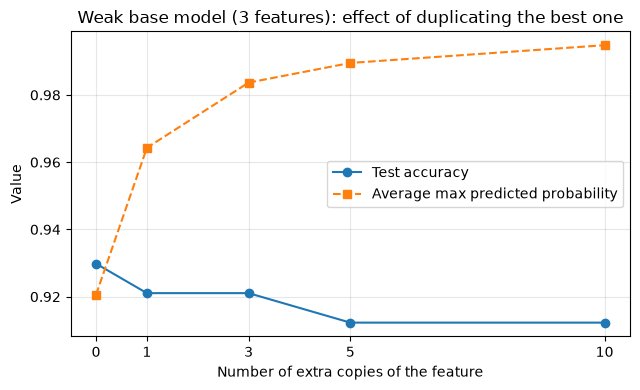

In [137]:
weak = list(np.argsort(score)[:2])           # two least informative features
base_cols = [best] + weak
accs2, confs2 = [], []
for n in copies_list:
    Xtr = add_copies(X_train[:, base_cols], 0, n); Xte = add_copies(X_test[:, base_cols], 0, n)
    mdl = GaussianNaiveBayes(var_smoothing=1e-9).fit(Xtr, y_train)
    accs2.append(accuracy(y_test, mdl.predict(Xte))); confs2.append(mdl.predict_proba(Xte).max(axis=1).mean())
print(f"{'extra copies':>12}{'accuracy':>10}{'avg max prob':>14}")
for n, a, c in zip(copies_list, accs2, confs2):
    print(f"{n:>12}{a:>10.4f}{c:>14.4f}")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(copies_list, accs2, "o-", label="Test accuracy")
ax.plot(copies_list, confs2, "s--", label="Average max predicted probability")
ax.set_xlabel("Number of extra copies of the feature"); ax.set_ylabel("Value")
ax.set_title("Weak base model (3 features): effect of duplicating the best one")
ax.set_xticks(copies_list); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [138]:
# Task 5:Fitted Gaussian curves
#plotted the fitted Gaussian curves of every class

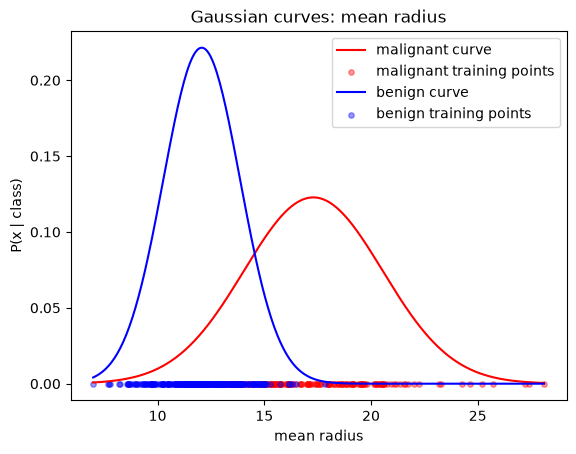

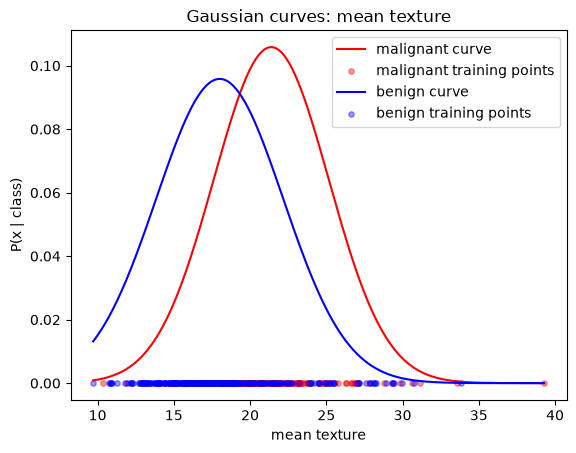

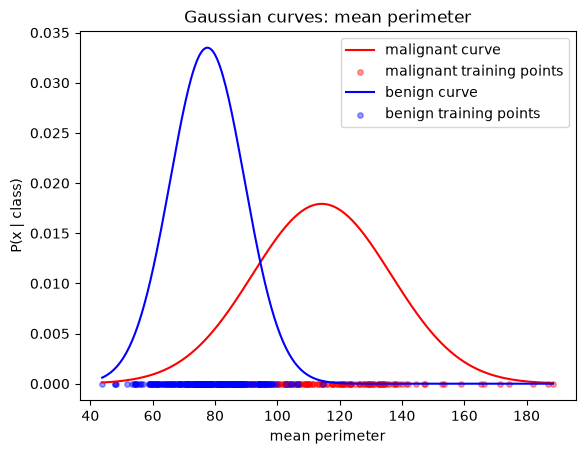

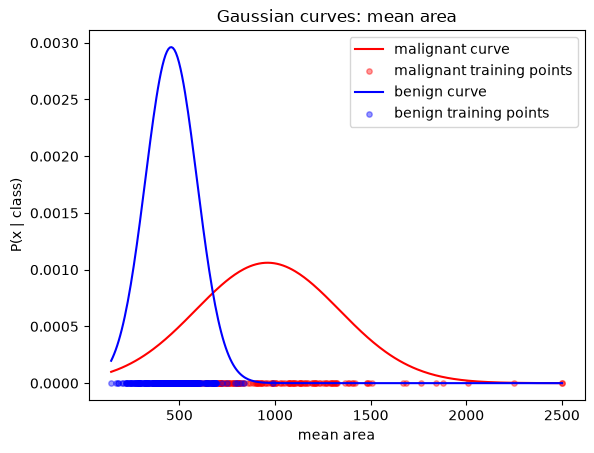

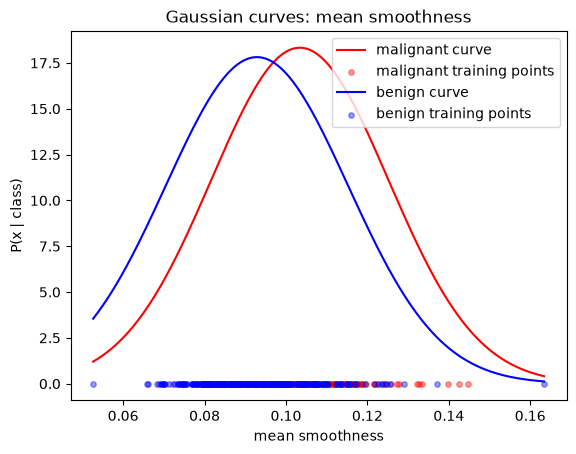

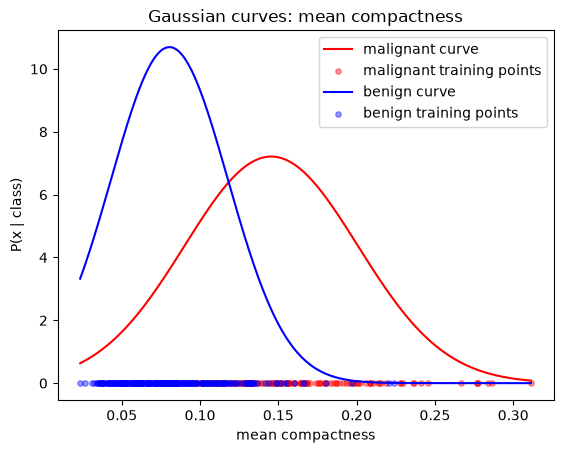

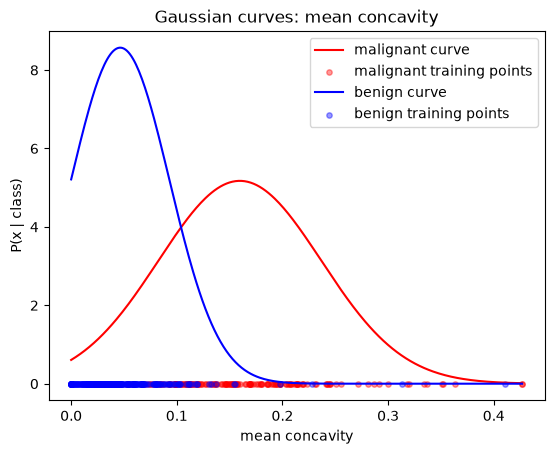

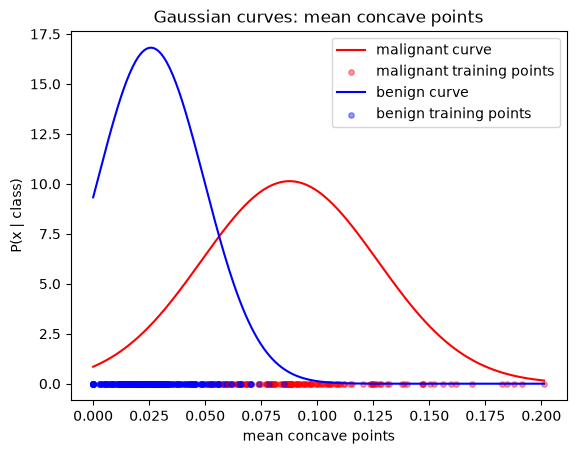

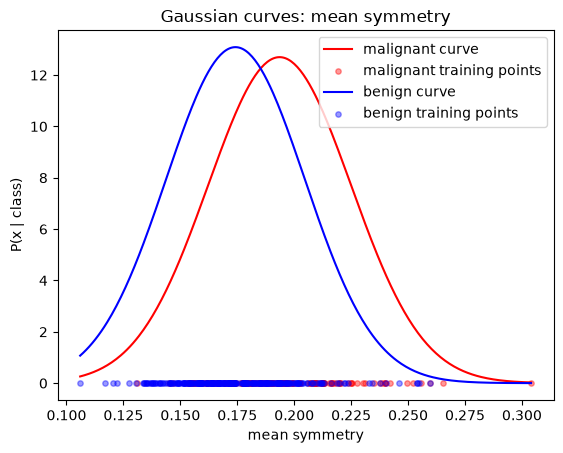

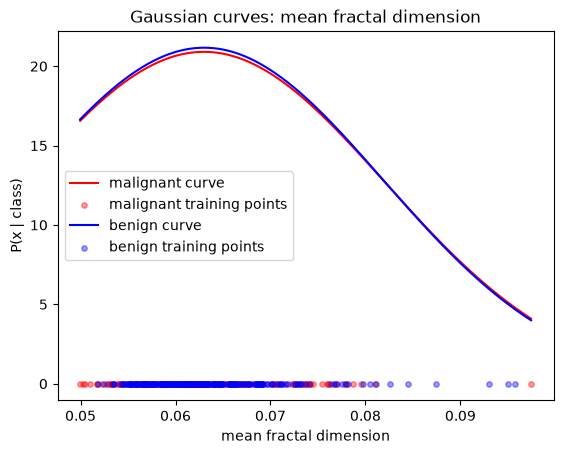

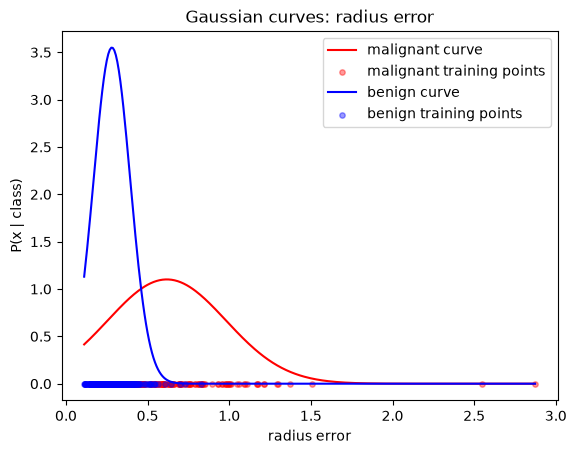

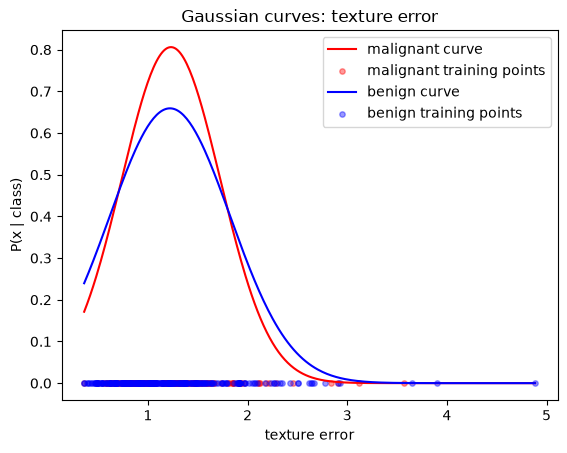

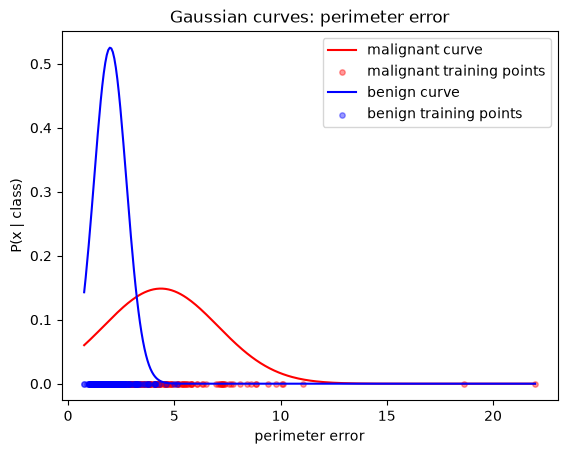

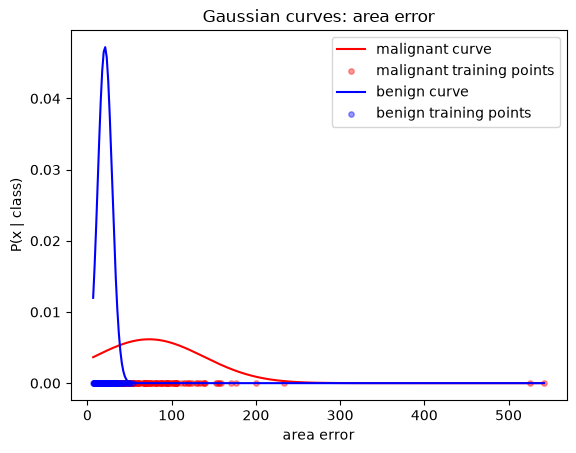

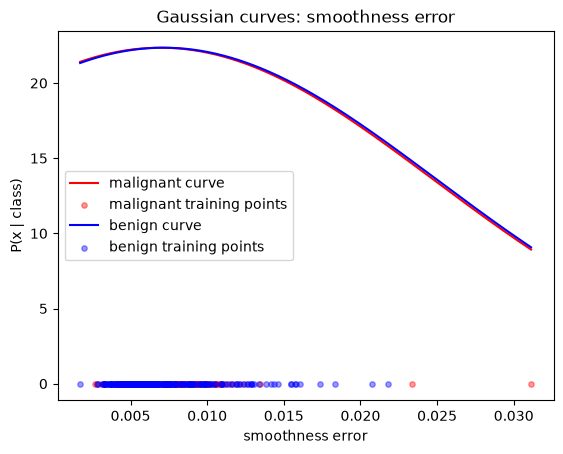

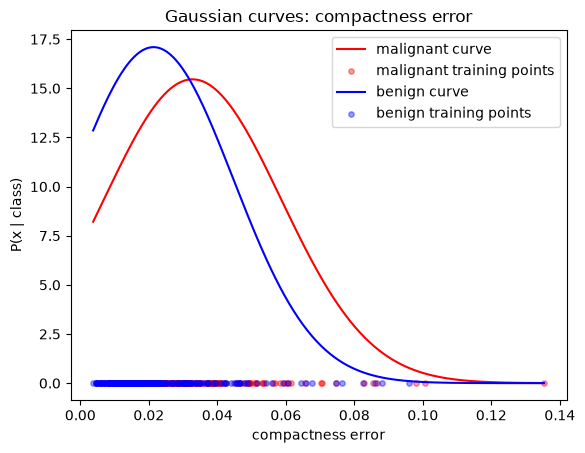

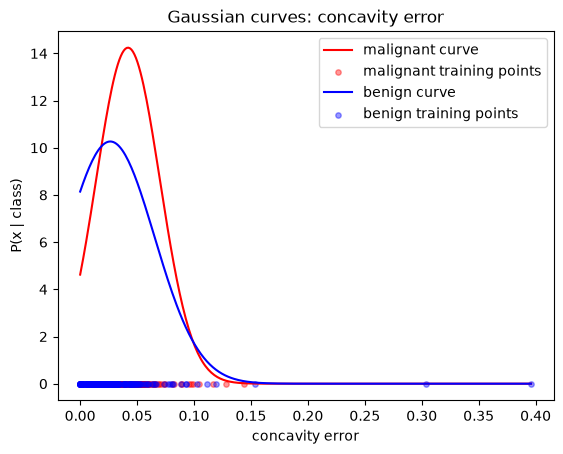

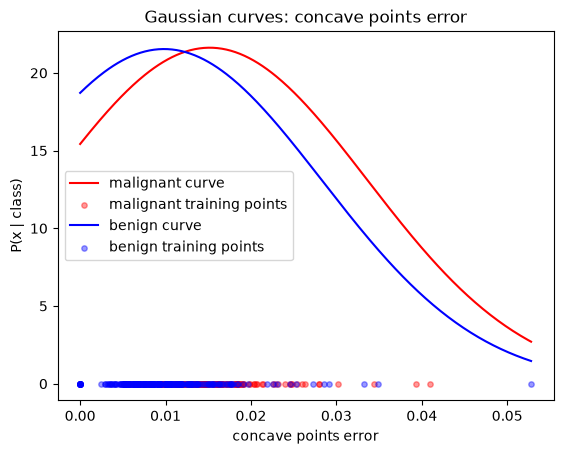

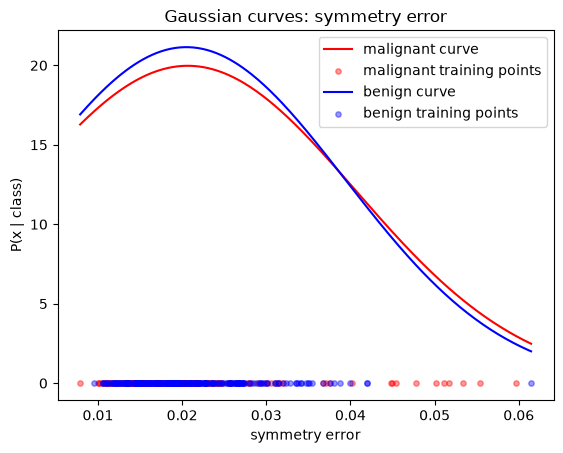

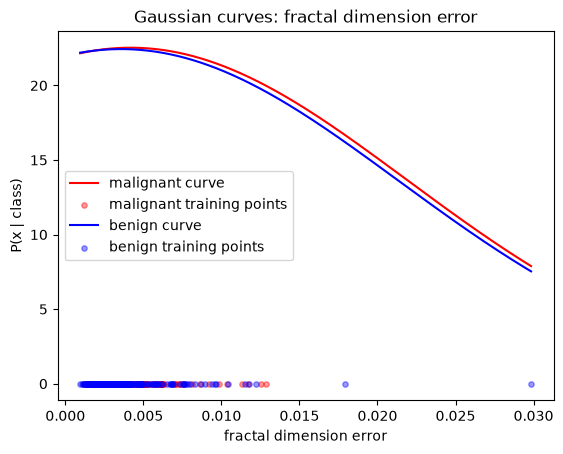

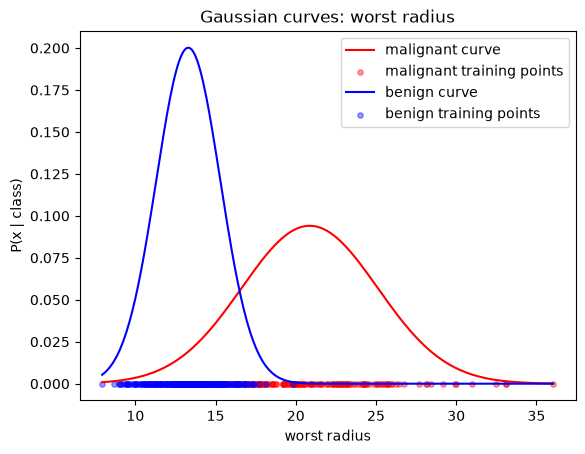

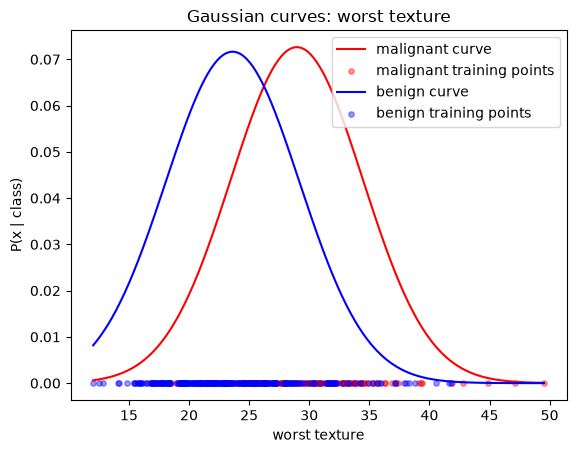

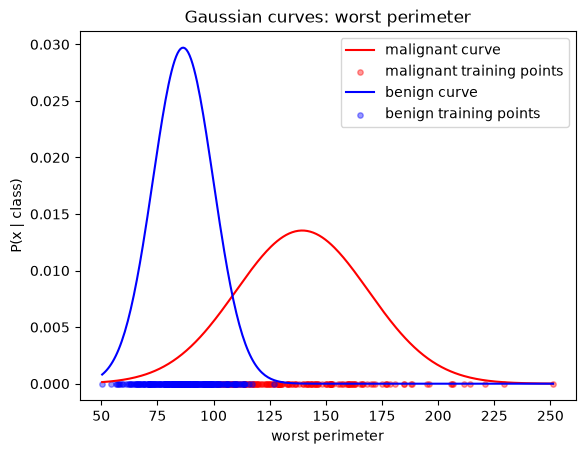

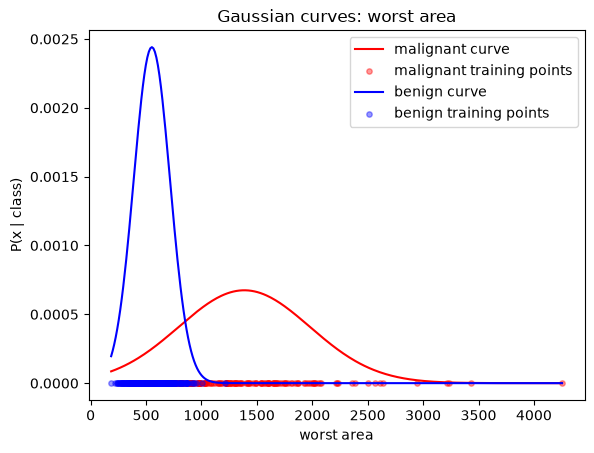

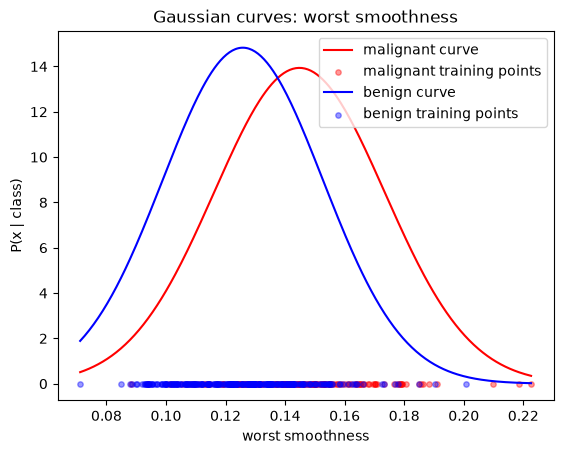

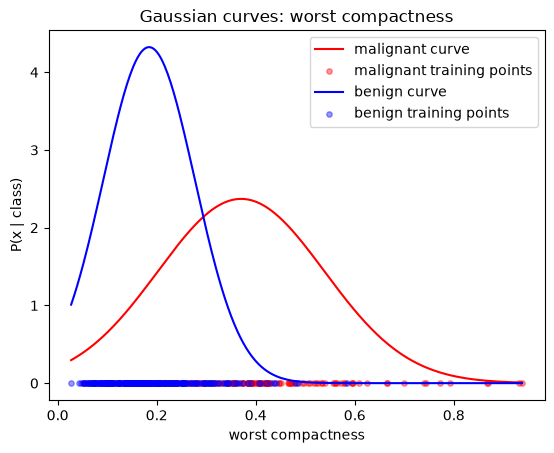

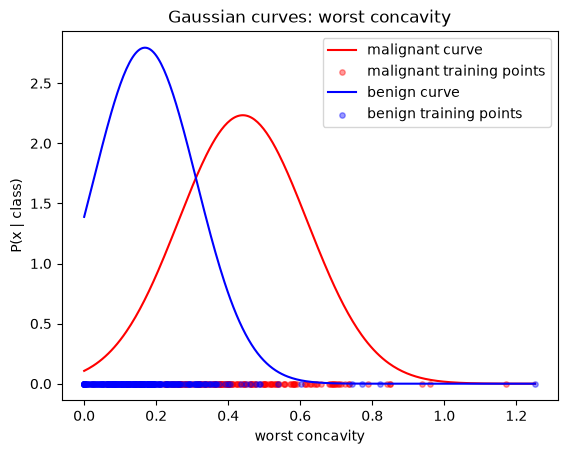

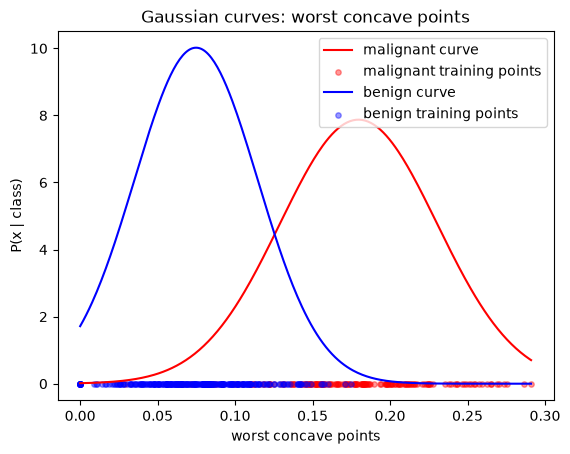

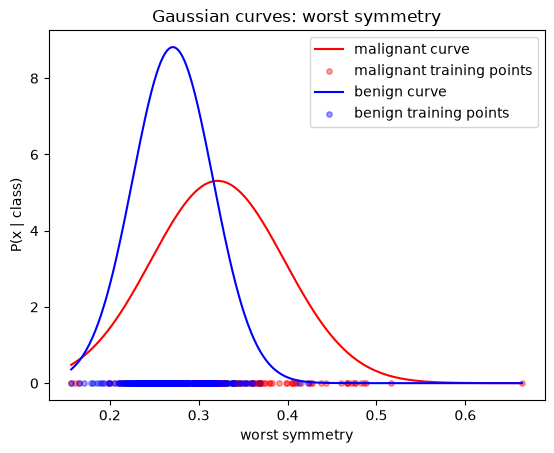

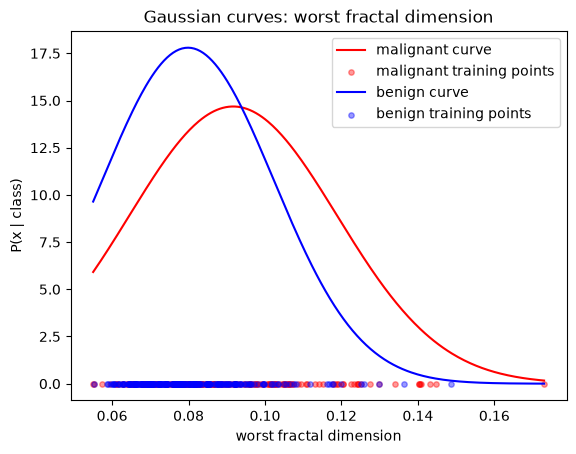

In [139]:
model = GaussianNaiveBayes().fit(X_train, y_train)
colors = ["red", "blue"]

for j in range(30):                      # one figure for each of the 30 features
    x = np.linspace(X_train[:, j].min(), X_train[:, j].max(), 300)

    for k in range(2):                   # k = 0 is malignant, k = 1 is benign
        mean = model.theta_[k, j]
        var = model.var_[k, j]
        curve = 1 / np.sqrt(2 * np.pi * var) * np.exp(-(x - mean) ** 2 / (2 * var))
        plt.plot(x, curve, color=colors[k], label=data.target_names[k] + " curve")

        points = X_train[y_train == k, j]
        plt.scatter(points, np.zeros(len(points)), color=colors[k], alpha=0.4, s=15,
                    label=data.target_names[k] + " training points")

    plt.title("Gaussian curves: " + data.feature_names[j])
    plt.xlabel(data.feature_names[j])
    plt.ylabel("P(x | class)")
    plt.legend()
    plt.show()

In [140]:
# Task 5B: Decision regions
# trained a GNB on two features only so the regions can be drawn in 2D
# predicted the class of every point on a mesh grid and plotted the test points on top

2-feature test accuracy: 0.9474


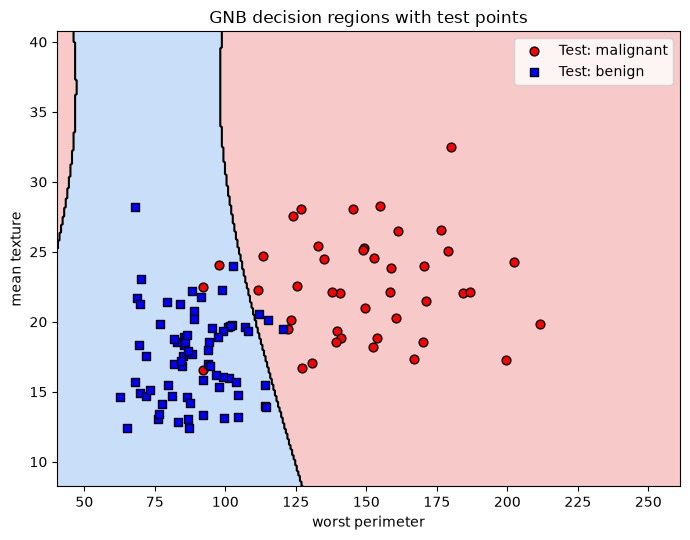

In [141]:
f1_name, f2_name = "worst perimeter", "mean texture"
f1, f2 = list(feature_names).index(f1_name), list(feature_names).index(f2_name)

X2_train, X2_test = X_train[:, [f1, f2]], X_test[:, [f1, f2]]
gnb2 = GaussianNaiveBayes(var_smoothing=1e-9).fit(X2_train, y_train)
print("2-feature test accuracy:", round(accuracy(y_test, gnb2.predict(X2_test)), 4))

pad1 = 0.05 * np.ptp(X[:, f1]); pad2 = 0.05 * np.ptp(X[:, f2])
xx, yy = np.meshgrid(np.linspace(X[:, f1].min()-pad1, X[:, f1].max()+pad1, 400),
                     np.linspace(X[:, f2].min()-pad2, X[:, f2].max()+pad2, 400))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = gnb2.predict(grid).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], colors=["#f4a6a6", "#a6c8f4"], alpha=0.6)
ax.contour(xx, yy, Z, levels=[0.5], colors="k", linewidths=1.5)
for c, col, mk in zip(gnb2.classes_, ["red", "blue"], ["o", "s"]):
    pts = X2_test[y_test == c]
    ax.scatter(pts[:, 0], pts[:, 1], c=col, marker=mk, edgecolor="k", s=40, label=f"Test: {class_names[c]}")
ax.set_xlabel(f1_name); ax.set_ylabel(f2_name)
ax.set_title("GNB decision regions with test points")
ax.legend(); plt.tight_layout(); plt.show()

In [142]:
# Task 6: Compare with scikit-learn
# trained sklearn GaussianNB with the same var_smoothing
# used np.allclose to compare theta_, var_, class_prior_ and predict_proba
# calculated the percentage of test samples where both models agree

In [143]:
from sklearn.naive_bayes import GaussianNB   # allowed ONLY in this task

VS = 1e-9
mine = GaussianNaiveBayes(var_smoothing=VS).fit(X_train, y_train)
sk = GaussianNB(var_smoothing=VS).fit(X_train, y_train)

print("theta_ match:       ", np.allclose(mine.theta_, sk.theta_))
print("var_ match:         ", np.allclose(mine.var_, sk.var_))
print("class_prior_ match: ", np.allclose(mine.class_prior_, sk.class_prior_))
print("predict_proba match:", np.allclose(mine.predict_proba(X_test), sk.predict_proba(X_test)))

agree = np.mean(mine.predict(X_test) == sk.predict(X_test)) * 100
print(f"\nPrediction agreement on test set: {agree:.2f}%")
print(f"Max |proba difference|: {np.abs(mine.predict_proba(X_test) - sk.predict_proba(X_test)).max():.2e}")

theta_ match:        True
var_ match:          True
class_prior_ match:  True
predict_proba match: True

Prediction agreement on test set: 100.00%
Max |proba difference|: 1.55e-15
